# Reference solution: hidden drivers of defects

This notebook solves the task the way a careful analyst would, using only `data/`.
It follows the three EDA steps from the task definition:

1. **Describe** the data (DDA): structure, quality issues, cleaning, A1-A4.
2. **Identify salient features**: leakage, regime change, direct drivers, B1-B3.
3. **Interpret salient features**: the supplier switch, the humidity optimum for Alpha resin and the cleaning counterfactual, C1-C3.

It produces `reference_answer.json` in the answer format of the task, then (section 4 only) checks it against the answer key.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

DATA = Path("../data")
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
pd.set_option("display.width", 140)

raw = pd.read_csv(DATA / "batches.csv", dtype={"production_date": str})
suppliers = pd.read_csv(DATA / "suppliers.csv")
maintenance = pd.read_csv(DATA / "maintenance.csv", parse_dates=["date"])
print(raw.shape, suppliers.shape, maintenance.shape)
raw.head()

(3060, 15) (3, 6) (75, 4)


,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
0,B-670945,01/06/2025,L1,Night,OP-01,SP-01,3.7,15.8,214.8,28.6,30.1,586,23,20.9,82.77
1,B-654357,01/06/2025,L1,N,OP-04,sp-01,6.9,14.6,206.1,27.6,31.1,354,10,20.9,36.44
2,B-299201,01/06/2025,L1,D,OP-06,SP-02,5.1,14.9,208.8,18.0,30.1,385,19,23.6,84.86
3,B-181224,01/06/2025,L1,Night,OP-02,SP-01,6.0,15.1,207.5,46.7,28.1,532,30,22.1,119.67
4,B-854898,2025-01-06,L2,Day,OP-12,SP-01,5.6,18.2,205.7,42.5,28.0,813,28,22.5,115.56


## 1. Describe the data

### 1.1 Structure and summary statistics

In [2]:
raw.dtypes.to_frame('dtype').T

,batch_id,production_date,line,shift,operator_id,supplier_code,machine_age_years,ambient_temp_c,mold_temp,humidity_pct,cycle_time_s,units_produced,defective_units,qc_inspection_min,rework_cost_eur
dtype,str,str,str,str,str,str,float64,float64,float64,float64,float64,int64,int64,float64,float64


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
machine_age_years,3060.0,7.19,4.69,1.00,4.20,5.40,7.40,21.50
ambient_temp_c,3060.0,21.94,4.62,10.40,17.60,23.10,25.90,30.60
mold_temp,3060.0,258.57,93.80,0.00,208.40,216.10,231.30,464.70
humidity_pct,3004.0,31.05,14.87,-1.00,21.30,30.10,41.40,72.30
cycle_time_s,3060.0,31.70,4.78,18.00,28.40,31.50,34.80,45.00
units_produced,3060.0,572.48,296.41,93.00,360.00,526.00,720.00,3387.00
defective_units,3060.0,31.52,26.50,1.00,15.00,24.00,40.00,380.00
qc_inspection_min,3060.0,22.05,3.59,7.50,20.40,22.10,24.00,48.40
rework_cost_eur,3060.0,139.56,119.29,4.12,65.38,105.18,175.98,1486.82


Two values stand out in `describe()` before any plotting:

- `humidity_pct` has a minimum of **-1**, which is impossible for relative humidity, so it is a sentinel for a missing reading.
- `mold_temp` has a minimum of **0** and a maximum above 400, both implausible for one unit of measurement.

### 1.2 Categorical columns

In [4]:
for col in ["line", "shift", "supplier_code"]:
    print(col, raw[col].map(repr).value_counts().to_dict(), "\n")

line {"'L1'": 873, "'L2'": 819, "'L3'": 746, "'L4'": 622} 

shift {"'Day'": 1460, "'Night'": 996, "'DAY'": 89, "'D'": 88, "' Day'": 86, "'day'": 86, "'NIGHT'": 72, "'night'": 65, "'Night '": 60, "'N'": 58} 

supplier_code {"'SP-01'": 1254, "'SP-03'": 666, "'SP-02'": 651, "' Sp-01'": 92, "'SP-01 '": 80, "'sp-01'": 67, "'SP-03 '": 54, "' Sp-02'": 51, "'sp-03'": 39, "' Sp-03'": 37, "'sp-02'": 36, "'SP-02 '": 33} 



`shift` has spelling variants of two values (`Day`, `day`, `D`, `' Day'`, ...), and `supplier_code` has case and whitespace variants of the three codes in `suppliers.csv`. A join on the raw key would silently drop rows.

### 1.3 Dates: one format per line

In [5]:
print(raw.groupby("line")["production_date"].agg(["first", "last"]))
try:
    pd.to_datetime(raw["production_date"])
except ValueError as e:
    print("\nplain to_datetime fails:", str(e).splitlines()[0])

           first        last
line                        
L1    01/06/2025  09/30/2025
L2    2025-01-06  2025-09-30
L3    2025-01-06  2025-09-30
L4    06/01/2025  30/09/2025

plain to_datetime fails: time data "2025-01-06" doesn't match format "%m/%d/%Y". You might want to try:


The lines do not share one date format: L2 and L3 write ISO dates, L1 writes `04/14/2025` and L4 writes `14/04/2025`. A global fallback is wrong either way: `format="mixed"` reads L4's `06/01/2025` as 1 June instead of 6 January, and `dayfirst=True` even misreads the ISO dates. Each line's export is internally consistent, so the right parser is the one format that parses **every** date of that line.

In [6]:
FORMATS = ("%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y")

def parse_dates(raw: pd.DataFrame) -> pd.Series:
    parts = []
    for line, s in raw.groupby("line")["production_date"]:
        fits = [f for f in FORMATS if pd.to_datetime(s, format=f, errors="coerce").notna().all()]
        assert len(fits) == 1, (line, fits)
        print(line, "->", fits[0])
        parts.append(pd.to_datetime(s, format=fits[0]))
    return pd.concat(parts).reindex(raw.index)

dates = parse_dates(raw)
print("range:", dates.min().date(), "to", dates.max().date())

L1 -> %m/%d/%Y
L2 -> %Y-%m-%d
L3 -> %Y-%m-%d
L4 -> %d/%m/%Y
range: 2025-01-06 to 2025-09-30


### 1.4 Duplicates

In [7]:
print("exact duplicate rows:", raw.duplicated().sum())
print("repeated batch_id:   ", raw["batch_id"].duplicated().sum())
dup_ids = raw.loc[raw["batch_id"].duplicated(), "batch_id"]
print("rows sharing a repeated id that are NOT exact copies:",
      (raw[raw["batch_id"].isin(dup_ids)].drop_duplicates()["batch_id"].duplicated()).sum())

exact duplicate rows: 60
repeated batch_id:    60
rows sharing a repeated id that are NOT exact copies: 0


Every repeated `batch_id` is an exact copy of another row (a double export), so dropping exact duplicates is safe and loses no information.

### 1.5 Mold temperature units

In [8]:
valid = raw[raw["mold_temp"] > 0]
print(valid.groupby("line")["mold_temp"].describe().round(1))
print("\nzeros per line:", raw[raw["mold_temp"] == 0].groupby("line").size().to_dict())

      count   mean   std    min    25%    50%    75%    max
line                                                       
L1    852.0  215.8   9.2  191.3  208.8  216.7  223.0  238.1
L2    809.0  211.0   7.0  189.3  206.4  211.0  216.1  232.2
L3    737.0  417.2  15.1  376.9  406.4  417.6  428.0  464.7
L4    613.0  210.8   7.0  184.8  206.1  210.9  215.6  232.3

zeros per line: {'L1': 21, 'L2': 10, 'L3': 9, 'L4': 9}


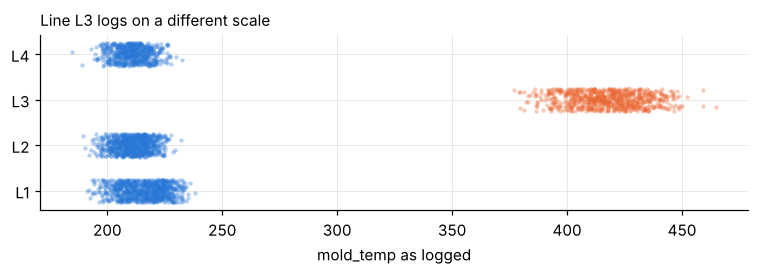

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (line, g) in enumerate(valid.groupby("line")):
    ax.scatter(g["mold_temp"], np.full(len(g), i) + np.random.default_rng(0).uniform(-0.25, 0.25, len(g)),
               s=8, color=ORANGE if line == "L3" else BLUE, alpha=0.35, linewidths=0)
ax.set_yticks(range(4), sorted(valid["line"].unique()))
ax.set_xlabel("mold_temp as logged")
ax.set_title("Line L3 logs on a different scale", loc="left", fontsize=10)
plt.tight_layout()

L3 sits around 410 while the other lines sit around 210. (410 - 32) × 5/9 ≈ 210, so **L3 logs in °F**. The zeros appear on every line and are sensor failures, not cold molds.

### 1.6 The other two files

In [10]:
print(suppliers.to_string(index=False), "\n")
print(maintenance["event"].value_counts().to_string(), "\n")
maintenance[maintenance["event"] != "mold_cleaning"]

supplier_code supplier_name resin_grade country pre_dried  recipe_cycle_time_s
        SP-01         Alpha     PP-H350      DE        no                   30
        SP-02          Beta     PP-H350      PL       yes                   30
        SP-03         Gamma     PP-H420      CZ       yes                   36 

event
mold_cleaning         74
sensor_replacement     1 



,date,line,event,note
33,2025-04-14,L1,sensor_replacement,Mold temperature sensor replaced.


Three facts that the batch table alone does not show:

- **Alpha resin is not pre-dried** (`pre_dried = no`). Undried resin absorbs moisture, so its response to hall humidity may differ from the other two. Section 3.2 tests this.
- **Each resin grade has its own process recipe**: PP-H420 (Gamma) runs a 36 s cycle, PP-H350 a 30 s cycle. So the cycle time of a batch depends on its supplier. Section 3.1 needs this.
- **L1's mold temperature sensor was replaced on 2025-04-14.** The log does not say whether the new sensor reads correctly, so the data have to tell.

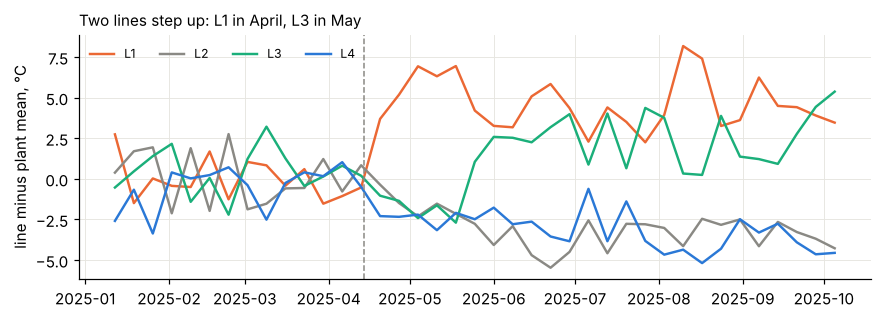

In [11]:
mt = raw[raw["mold_temp"] > 0].assign(date=dates[raw["mold_temp"] > 0])
mt.loc[mt["line"] == "L3", "mold_temp"] = (mt.loc[mt["line"] == "L3", "mold_temp"] - 32) * 5 / 9
weekly_t = mt.groupby([pd.Grouper(key="date", freq="W"), "line"])["mold_temp"].mean().unstack()
gap = weekly_t.sub(weekly_t.mean(axis=1), axis=0)   # each line against the plant mean (removes season)
fig, ax = plt.subplots(figsize=(8, 3))
for line, c in zip(gap, [ORANGE, GRAY, AQUA, BLUE]):
    ax.plot(gap.index, gap[line], color=c, lw=1.6, label=line)
ax.axvline(pd.Timestamp("2025-04-14"), color=GRAY, lw=1, ls="--")
ax.legend(ncol=4, frameon=False, fontsize=8); ax.set_ylabel("line minus plant mean, °C")
ax.set_title("Two lines step up: L1 in April, L3 in May", loc="left", fontsize=10)
plt.tight_layout()

Two lines step up, L1 at the sensor replacement and L3 in the second half of May, with no log entry. A step in a reading is either a biased sensor or a real change of the process, and the defects tell them apart: a hotter mold makes more defects (mold temperature is a strong driver, section 2.4), a biased sensor does not. The check measures, for each step, the jump of the reading and of the defect logit against L4, which has no step (L2 has its own regime change in June, section 2.3).

In [12]:
def step(line, since, until="2026-01-01"):
    """Difference in differences of the reading (against L2 and L4, adjusted for the hall
    temperature) and of the defect logit (against L4, since L2 has its own regime change)."""
    d = mt.assign(defects=raw["defective_units"], n=raw["units_produced"]).drop_duplicates("batch_id")
    d = d[d["date"] < until]
    r = d[d["line"].isin([line, "L2", "L4"])]
    on, post = r["line"] == line, (r["line"] == line) & (r["date"] >= since)
    X = np.column_stack([np.ones(len(r)), on, r["ambient_temp_c"], post])
    reading = np.linalg.lstsq(X, r["mold_temp"].to_numpy(), rcond=None)[0][-1]
    q = d[d["line"].isin([line, "L4"])]
    on, after = q["line"] == line, q["date"] >= since
    lg = lambda g: np.log(g["defects"].sum() / (g["n"].sum() - g["defects"].sum()))
    logit = (lg(q[on & after]) - lg(q[on & ~after])) - (lg(q[~on & after]) - lg(q[~on & ~after]))
    return pd.Series({"reading jump °C": reading, "defect-logit jump": logit,
                      "jump if real (0.03/°C)": 0.03 * reading}).round(2)

l3_start = (gap["L3"].diff().idxmax() - pd.Timedelta(days=6)).date()   # weekly labels mark the week's end
steps = pd.DataFrame({"L1 from 2025-04-14": step("L1", "2025-04-14"),
                      f"L3 from {l3_start}": step("L3", str(l3_start), until="2025-07-21")})
print(steps.to_string())
SENSOR_OFFSET = steps.iloc[0, 0]

                        L1 from 2025-04-14  L3 from 2025-05-19
reading jump °C                       7.54                5.88
defect-logit jump                    -0.05                0.11
jump if real (0.03/°C)                0.23                0.18


The last row uses the effect of mold temperature on the defect logit, about 0.03 per °C (the `mold_temp` slope of the binomial model in section 2.3).

- **L1**: the reading jumps by 7-8 °C, which would add about 0.2 to the logit if it were real, but the defects do not rise. **The new sensor reads high**, so the measured offset is subtracted from L1 readings from 2025-04-14 on.
- **L3**: the reading jumps by about 6 °C and the defect logit rises by about 0.1, the same order as the 0.18 a real 6 °C rise predicts and far from L1's zero. **L3 really runs warmer** (a setpoint change), so its readings stay as they are. (The comparison stops on 2025-07-21 because of the L3 QC change found in section 2.1.)

**Cleaning intervals.** The log also records when each line's molds were cleaned. The interval between cleanings is a candidate driver that is not a column of `batches.csv`.

In [13]:
cl = maintenance[maintenance["event"] == "mold_cleaning"].sort_values(["line", "date"]).copy()
cl["interval_days"] = cl.groupby("line")["date"].diff().dt.days
cl.groupby(cl["date"].dt.month)["interval_days"].mean().round(1).to_frame("mean interval, days").T

date,1,2,3,4,5,6,7,8,9,12
"mean interval, days",14.0,12.7,12.1,13.5,13.2,11.7,18.2,30.3,23.1,NaN


Cleanings normally happen every 10-16 days, but in July and August the interval roughly doubles (holidays), and the long gaps reach into early September. For each batch, **days since its line's last cleaning** comes from a backward as-of join: the last cleaning on or before the production date, because cleanings happen before the first shift.

### 1.7 Cleaning

In [14]:
def clean(raw: pd.DataFrame, suppliers: pd.DataFrame, maintenance: pd.DataFrame) -> pd.DataFrame:
    df = raw.drop_duplicates().copy()
    df["shift"] = df["shift"].str.strip().str[0].str.upper().map({"D": "Day", "N": "Night"})
    df["supplier_code"] = df["supplier_code"].str.strip().str.upper()
    df = df.merge(suppliers, on="supplier_code", how="left", validate="many_to_one")
    df["humidity_pct"] = df["humidity_pct"].where(df["humidity_pct"] >= 0)   # -1 -> NaN
    df["mold_temp"] = df["mold_temp"].where(df["mold_temp"] > 0)             # 0 -> NaN
    is_f = df["line"] == "L3"
    df.loc[is_f, "mold_temp"] = (df.loc[is_f, "mold_temp"] - 32) * 5 / 9   # degF -> degC
    df["production_date"] = parse_dates(df)                                   # one format per line
    drift = (df["line"] == "L1") & (df["production_date"] >= "2025-04-14")
    df.loc[drift, "mold_temp"] -= round(SENSOR_OFFSET, 1)                     # biased L1 sensor
    cleanings = (maintenance.loc[maintenance["event"] == "mold_cleaning", ["line", "date"]]
                 .rename(columns={"date": "cleaned_on"}).sort_values("cleaned_on"))
    df = pd.merge_asof(df.sort_values("production_date"), cleanings, left_on="production_date",
                       right_on="cleaned_on", by="line", direction="backward")
    df["days_since_cleaning"] = (df["production_date"] - df["cleaned_on"]).dt.days
    df["rate"] = df["defective_units"] / df["units_produced"]
    return df.drop(columns="cleaned_on").sort_values("batch_id").reset_index(drop=True)

df = clean(raw, suppliers, maintenance)
assert df["days_since_cleaning"].notna().all()
assert df["shift"].notna().all() and df["supplier_name"].notna().all()
assert df.groupby("line")["mold_temp"].median().between(195, 225).all()
print(df.shape)
df[["shift", "supplier_name"]].value_counts().unstack()

L1 -> %m/%d/%Y
L2 -> %Y-%m-%d
L3 -> %Y-%m-%d
L4 -> %d/%m/%Y
(3000, 22)


supplier_name,Alpha,Gamma,Beta
shift,,,
Day,852,460,460
Night,616,317,295


### 1.8 Answers A1-A4

In [15]:
answers = {}
answers["A1_unique_batches"] = int(df["batch_id"].nunique())
answers["A2_missing_humidity_batches"] = int(df["humidity_pct"].isna().sum())
answers["A3_overall_defect_rate"] = round(float(df["defective_units"].sum() / df["units_produced"].sum()), 5)
answers["A4_median_mold_temp_c"] = round(float(df["mold_temp"].median()), 2)

print("mean of batch rates (not the overall rate):", round(df["rate"].mean(), 5))
print("missing humidity, NaN only (sentinels ignored):", raw.drop_duplicates()["humidity_pct"].isna().sum())
print("median mold temperature without the L1 sensor correction:",
      round(float(df["mold_temp"].where(~((df["line"] == "L1") & (df["production_date"] >= "2025-04-14")),
                                        df["mold_temp"] + round(SENSOR_OFFSET, 1)).median()), 2))
answers

mean of batch rates (not the overall rate): 0.05939
missing humidity, NaN only (sentinels ignored): 55
median mold temperature without the L1 sensor correction: 212.8


{'A1_unique_batches': 3000,
 'A2_missing_humidity_batches': 226,
 'A3_overall_defect_rate': 0.05503,
 'A4_median_mold_temp_c': 211.6}

The overall defect rate is the share of *all produced units* that were defective, so it is a pooled ratio. The mean of batch rates differs because the worst line also makes the smallest batches, which gives each of its few units too much weight.

## 2. Identify salient features

### 2.1 Leakage: columns determined by the outcome

In [16]:
num = df.select_dtypes("number").drop(columns=["rate"])
num.corrwith(df["defective_units"]).sort_values(ascending=False).round(3).to_frame("r with defective_units")

,r with defective_units
defective_units,1.000
rework_cost_eur,0.945
qc_inspection_min,0.630
units_produced,0.516
mold_temp,0.283
days_since_cleaning,0.219
ambient_temp_c,0.210
humidity_pct,0.055
recipe_cycle_time_s,-0.076
machine_age_years,-0.104


In [17]:
ratio = df["rework_cost_eur"] / df["defective_units"].replace(0, np.nan)
print("rework cost per defective part: median", round(ratio.median(), 2), "IQR", ratio.quantile([.25, .75]).round(2).tolist())
slope = np.polyfit(df["defective_units"], df["qc_inspection_min"], 1)
print(f"qc minutes = {slope[1]:.1f} + {slope[0]:.3f} x defective_units")

rework cost per defective part: median 4.22 IQR [3.94, 4.55]
qc minutes = 19.4 + 0.085 x defective_units


`rework_cost_eur` is about 4.2 € per defective part, and `qc_inspection_min` grows with the number of defects found. Both are **recorded after quality control and computed from the outcome**. They are excellent "predictors" only because they encode Y, so they must be excluded from any driver analysis (B2).

They are still useful as an **audit trail of the outcome**. Rework is booked for every defective part that gets reworked, so the cost per *recorded* defect should be stable. It is not:

L3 change: 2025-07-21


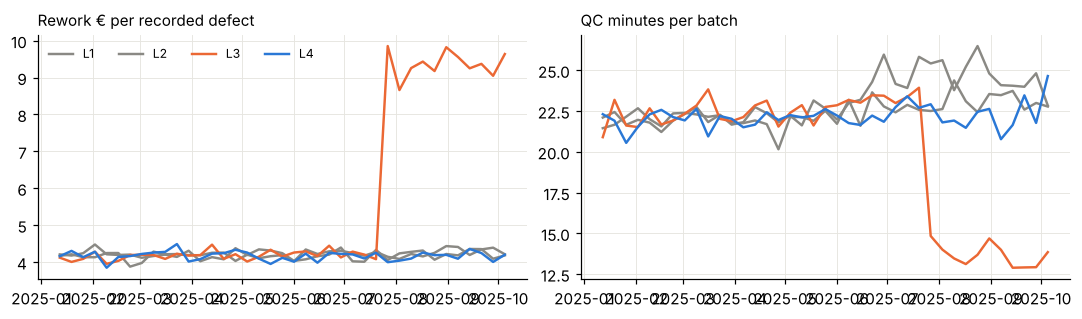

In [18]:
audit = df[df["defective_units"] > 0].assign(cost_per_defect=ratio)
wk = audit.groupby([pd.Grouper(key="production_date", freq="W"), "line"]).agg(
    cost=("cost_per_defect", "median"), qc=("qc_inspection_min", "mean")).unstack()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for line, c in zip(wk["cost"], [GRAY, GRAY, ORANGE, BLUE]):
    axes[0].plot(wk.index, wk["cost"][line], color=c, lw=1.6, label=line)
    axes[1].plot(wk.index, wk["qc"][line], color=c, lw=1.6)
axes[0].set_title("Rework € per recorded defect", loc="left", fontsize=10); axes[0].legend(ncol=4, frameon=False, fontsize=8)
axes[1].set_title("QC minutes per batch", loc="left", fontsize=10)
plt.tight_layout()

l3 = audit[audit["line"] == "L3"].set_index("production_date")["cost_per_defect"]
qc_date = max(l3.index.unique()[20:-20], key=lambda d: l3[l3.index >= d].mean() - l3[l3.index < d].mean())
print("L3 change:", qc_date.date())

From late July, **L3 books about twice the rework per recorded defect and spends about 8 minutes less on QC per batch**. The parts are as bad as before (rework still has to fix them), but QC records fewer of them: L3 switched to a quicker inspection that misses about half of the defective parts. The fall in L3's recorded defect rate from that date is a change in measurement, not in production. Every model below gets an indicator `qc_change` for it, and B3 must not report it as a change of the process.

In [19]:
df["qc_change"] = ((df["line"] == "L3") & (df["production_date"] >= qc_date)).astype(int)

### 2.2 Univariate view: what a correlation matrix would suggest

In [20]:
cands = ["mold_temp", "humidity_pct", "cycle_time_s", "machine_age_years", "ambient_temp_c", "days_since_cleaning"]
df[cands].corrwith(df["rate"]).round(3).to_frame("Pearson r with defect rate")

,Pearson r with defect rate
mold_temp,0.286
humidity_pct,0.012
cycle_time_s,-0.280
machine_age_years,0.392
ambient_temp_c,0.241
days_since_cleaning,0.242


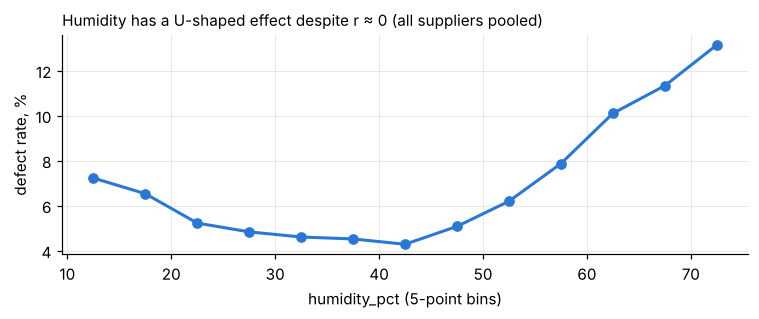

In [21]:
bins = pd.cut(df["humidity_pct"], np.arange(10, 81, 5))
by_hum = df.groupby(bins, observed=True).apply(lambda g: g["defective_units"].sum() / g["units_produced"].sum())
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([b.mid for b in by_hum.index], by_hum.values * 100, color=BLUE, lw=2, marker="o", ms=6)
ax.set_xlabel("humidity_pct (5-point bins)"); ax.set_ylabel("defect rate, %")
ax.set_title("Humidity has a U-shaped effect despite r ≈ 0 (all suppliers pooled)", loc="left", fontsize=10)
plt.tight_layout()

Pearson r for humidity is close to 0, yet the binned rate is clearly U-shaped. Linear correlation cannot see a symmetric non-linear effect. `machine_age_years` and `ambient_temp_c`, on the other hand, correlate with the rate. Section 2.4 tests whether those correlations are direct effects or confounding.

### 2.3 Regime change over time

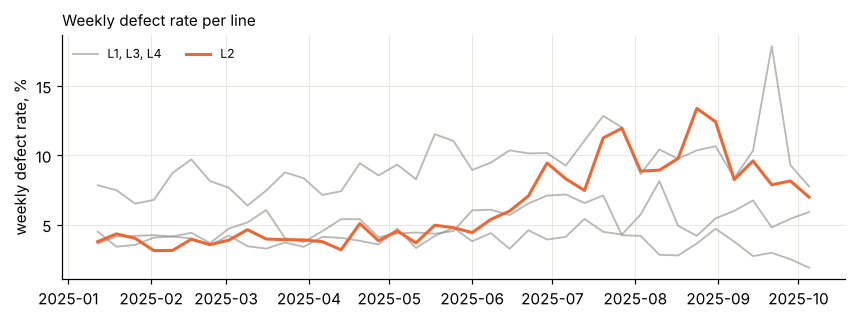

In [22]:
weekly = (df.set_index("production_date").groupby("line")[["defective_units", "units_produced"]]
          .resample("W").sum())
weekly = (weekly["defective_units"] / weekly["units_produced"]).unstack(0)
fig, ax = plt.subplots(figsize=(8, 3))
others = [l for l in weekly if l != "L2"]
for k, line in enumerate(others):
    ax.plot(weekly.index, weekly[line] * 100, lw=1.2, color=GRAY, alpha=0.6,
            label=", ".join(others) if k == 0 else None)
ax.plot(weekly.index, weekly["L2"] * 100, lw=2, color=ORANGE, label="L2")
ax.legend(ncol=2, frameon=False, fontsize=8); ax.set_ylabel("weekly defect rate, %")
ax.set_title("Weekly defect rate per line", loc="left", fontsize=10)
plt.tight_layout()

All lines drift up in summer (hotter hall, hotter molds, and longer gaps between mold cleanings), so a changepoint search on raw rates would be confounded by season. The search below therefore runs on **observed / expected** defects, where *expected* comes from a model of the process variables, including days since cleaning, without any time term. For each line it finds the single split date that maximizes the Poisson log-likelihood ratio.

In [23]:
HUMIDITY = "C(supplier_name):humidity_pct + C(supplier_name):I(humidity_pct**2)"
base_formula = (f"rate ~ C(line) + C(supplier_name) + C(shift) + mold_temp + {HUMIDITY}"
                " + cycle_time_s + days_since_cleaning + qc_change")
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
base = smf.glm(base_formula, model_df, family=sm.families.Binomial(),
               var_weights=model_df["units_produced"]).fit(scale="X2")
model_df["expected"] = base.predict(model_df) * model_df["units_produced"]

def best_split(g: pd.DataFrame, margin_days: int = 14):
    daily = g.groupby("production_date")[["defective_units", "expected"]].sum().sort_index()
    o, e = daily["defective_units"].to_numpy(), daily["expected"].to_numpy()
    co, ce = o.cumsum(), e.cumsum()
    def seg(oo, ee): return oo * np.log(oo / ee)
    total = seg(co[-1], ce[-1])
    llr = [seg(co[i - 1], ce[i - 1]) + seg(co[-1] - co[i - 1], ce[-1] - ce[i - 1]) - total
           for i in range(margin_days, len(o) - margin_days)]
    i = int(np.argmax(llr)) + margin_days
    return daily.index[i].date(), float(max(llr)), co[i - 1] / ce[i - 1], (co[-1] - co[i - 1]) / (ce[-1] - ce[i - 1])

splits = pd.DataFrame([(l, *best_split(g)) for l, g in model_df.groupby("line")],
                      columns=["line", "split_date", "LLR", "O/E before", "O/E after"]).set_index("line")
splits.round(3)

,split_date,LLR,O/E before,O/E after
line,,,,
L1,2025-02-11,24.037,1.143,0.984
L2,2025-06-16,1131.267,0.751,1.313
L3,2025-09-04,5.583,0.995,1.118
L4,2025-06-30,10.092,1.028,0.951


Only L2 shows a large likelihood ratio: its observed/expected defect ratio jumps by a large factor at one date. The other lines' best splits are noise of much smaller magnitude. Without the `qc_change` term, L3's drop in late July would show up as a second, spurious "regime change" (a fall in *recorded* defects only):

In [24]:
base_noqc = smf.glm(base_formula.replace(" + qc_change", ""), model_df, family=sm.families.Binomial(),
                    var_weights=model_df["units_produced"]).fit(scale="X2")
l3_df = model_df[model_df["line"] == "L3"].assign(expected=lambda d: base_noqc.predict(d) * d["units_produced"])
print("L3 best split without the QC indicator:", best_split(l3_df)[:2])

L3 best split without the QC indicator: (datetime.date(2025, 7, 21), 1020.5942175689933)


In [25]:
regime_line = splits["LLR"].idxmax()
regime_date = splits.loc[regime_line, "split_date"]
df["regime"] = ((df["line"] == regime_line) & (df["production_date"] >= pd.Timestamp(regime_date))).astype(int)
answers["B3_regime_change"] = {"line": regime_line, "date": str(regime_date)}
answers["B3_regime_change"]

{'line': 'L2', 'date': '2025-06-16'}

### 2.4 Direct drivers: one multivariable model

Each batch is one observation of a noisy process. Besides binomial sampling noise, batches differ by an unobserved batch-level factor, so a large batch is *not* proportionally more informative than a small one. The model is therefore an OLS on the **empirical logit** of each batch, `log((d + 0.5) / (n - d + 0.5))`, with heteroskedasticity-robust (HC3) standard errors. It contains every candidate variable plus the controls (line, supplier, regime, days since cleaning) and a humidity curve per supplier (section 3.2 shows why). A variable with a *direct* effect keeps a clear signal when everything else is held fixed, while a confounded one loses it.

In [26]:
model_df = df.dropna(subset=["mold_temp", "humidity_pct"]).copy()
model_df["y"] = np.log((model_df["defective_units"] + 0.5) / (model_df["units_produced"] - model_df["defective_units"] + 0.5))
full_formula = (f"y ~ C(line) + C(supplier_name) + C(shift) + mold_temp + {HUMIDITY}"
                " + cycle_time_s + machine_age_years + ambient_temp_c + regime + qc_change + days_since_cleaning")
full = smf.ols(full_formula, model_df).fit(cov_type="HC3")
print(full.summary().tables[1])

                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercept                                       -7.4466      0.215    -34.587      0.000      -7.869      -7.025
C(line)[T.L2]                                    0.0709      0.021      3.399      0.001       0.030       0.112
C(line)[T.L3]                                    0.2097      0.019     11.217      0.000       0.173       0.246
C(line)[T.L4]                                    0.9376      0.048     19.550      0.000       0.844       1.032
C(supplier_name)[T.Beta]                         0.8082      0.103      7.859      0.000       0.607       1.010
C(supplier_name)[T.Gamma]                        0.9923      0.102      9.686      0.000       0.792       1.193
C(shift)[T.Night]                                0.1653      0.013     12.764      0.000       0

In [27]:
op_model = smf.ols(full_formula.replace("C(line)", "C(operator_id)"), model_df).fit()
tests = {
    "mold_temp": full.pvalues["mold_temp"],
    "humidity_pct (all curve terms)": float(full.f_test(
        ", ".join(f"{k} = 0" for k in full.params.index if "humidity_pct" in k)).pvalue),
    "cycle_time_s": full.pvalues["cycle_time_s"],
    "shift": full.pvalues["C(shift)[T.Night]"],
    "machine_age_years": full.pvalues["machine_age_years"],
    "ambient_temp_c": full.pvalues["ambient_temp_c"],
    # operator_id is nested in line: does replacing line dummies by operator dummies add anything?
    "operator_id (within line)": op_model.compare_f_test(smf.ols(full_formula, model_df).fit())[1],
}
pd.Series(tests, name="p-value").map(lambda p: f"{p:.2e}").to_frame()

,p-value
mold_temp,2.11e-179
humidity_pct (all curve terms),0.00e+00
cycle_time_s,1.15e-153
shift,2.61e-37
machine_age_years,9.13e-01
ambient_temp_c,5.44e-01
operator_id (within line),7.30e-01


Mold temperature, humidity, cycle time and shift are overwhelmingly significant (p < 0.001). Machine age, ambient temperature and operator add nothing once line and mold temperature are in the model:

- **Machine age** correlates with defects only because the oldest presses are on L4, the worst line.
- **Ambient temperature** acts *through* mold temperature (a hot hall heats the molds), and the hot months are also the months with long cleaning gaps. With both in the model it has no effect of its own.
- **Operators** are tied to lines, and their apparent differences are line differences.

Leaving out the maintenance log turns ambient temperature into a false driver:

In [28]:
no_log = smf.ols(full_formula.replace(" + days_since_cleaning", ""), model_df).fit(cov_type="HC3")
print(f"ambient_temp_c without days since cleaning: p = {no_log.pvalues['ambient_temp_c']:.1e}")
print(f"ambient_temp_c with days since cleaning:    p = {full.pvalues['ambient_temp_c']:.2f}")
print(f"days_since_cleaning: +{full.params['days_since_cleaning']:.4f} logit per day, p = {full.pvalues['days_since_cleaning']:.1e}")

ambient_temp_c without days since cleaning: p = 1.6e-02
ambient_temp_c with days since cleaning:    p = 0.54
days_since_cleaning: +0.0199 logit per day, p = 6.9e-97


#### Side note: a tempting model that gets this wrong

A binomial GLM weighted by batch size looks like the textbook choice for defect counts. It assumes that a batch of 1,000 parts carries twice the information of a batch of 500. With batch-level variation that is false, the standard errors shrink too much, and null effects start to look significant:

In [29]:
glm_df = model_df.assign(rate=model_df["defective_units"] / model_df["units_produced"])
glm = lambda f: smf.glm(f.replace("y ~", "rate ~"), glm_df, family=sm.families.Binomial(),
                        var_weights=glm_df["units_produced"]).fit(scale="X2")
g_full, g_op = glm(full_formula), glm(full_formula.replace("C(line)", "C(operator_id)"))
from scipy import stats
F = (g_full.deviance - g_op.deviance) / (g_full.df_resid - g_op.df_resid) / g_op.scale
print("weighted quasi-binomial GLM, operator within line: p =",
      f"{stats.f.sf(F, g_full.df_resid - g_op.df_resid, g_op.df_resid):.1e}")
print("weighted quasi-binomial GLM, machine age:          p =", f"{g_full.pvalues['machine_age_years']:.1e}")

weighted quasi-binomial GLM, operator within line: p = 1.2e-02
weighted quasi-binomial GLM, machine age:          p = 1.3e-01


With this seed the weighted GLM declares the operator effect significant at p < 0.001, even though the operators have no effect by construction. Across 20 seeds the empirical-logit OLS recovered exactly the true driver set every time (`tests/test_reference.py`). This is a statistical trap that comes from the noise structure, which is realistic for production data.

In [30]:
name_map = {"mold_temp": "mold_temp", "humidity_pct (all curve terms)": "humidity_pct",
            "cycle_time_s": "cycle_time_s", "shift": "shift", "machine_age_years": "machine_age_years",
            "ambient_temp_c": "ambient_temp_c", "operator_id (within line)": "operator_id"}
answers["B1_direct_drivers"] = sorted(name_map[k] for k, p in tests.items() if p < 0.001)
answers["B2_leakage_columns"] = ["qc_inspection_min", "rework_cost_eur"]
answers["B1_direct_drivers"], answers["B2_leakage_columns"]

(['cycle_time_s', 'humidity_pct', 'mold_temp', 'shift'],
 ['qc_inspection_min', 'rework_cost_eur'])

## 3. Interpret salient features

### 3.1 Which single supplier would be best? (Simpson's paradox and a mediator)

In [31]:
pooled = lambda g: g["defective_units"].sum() / g["units_produced"].sum()
overall = df.groupby("supplier_name").apply(pooled).rename("overall")
within = df.groupby(["line", "supplier_name"]).apply(pooled).unstack()
alloc = pd.crosstab(df["line"], df["supplier_name"], normalize="columns").round(2)
print("Defect rate overall:\n", (overall * 100).round(2).to_string(), "\n")
print("Defect rate within each line (%):\n", (within * 100).round(2), "\n")
print("Where each supplier's batches go (share of supplier's batches):\n", alloc)

Defect rate overall:
 supplier_name
Alpha    5.58
Beta     6.51
Gamma    4.66 

Defect rate within each line (%):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              4.72  3.90   3.98
L2              6.57  5.74   5.46
L3              5.12  4.38   4.05
L4             10.62  9.34   8.25 

Where each supplier's batches go (share of supplier's batches):
 supplier_name  Alpha  Beta  Gamma
line                             
L1              0.36  0.12   0.30
L2              0.34  0.11   0.29
L3              0.26  0.15   0.31
L4              0.04  0.63   0.10


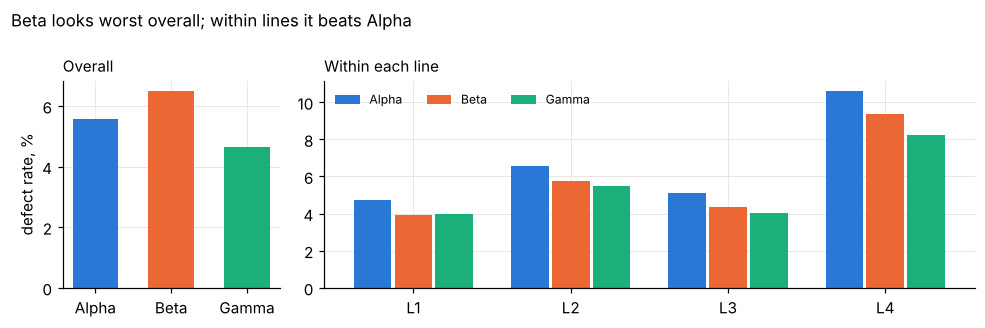

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 3]})
colors = {"Alpha": BLUE, "Beta": ORANGE, "Gamma": AQUA}
axes[0].bar(overall.index, overall * 100, color=[colors[s] for s in overall.index], width=0.6)
axes[0].set_title("Overall", loc="left", fontsize=10); axes[0].set_ylabel("defect rate, %")
w = 0.26
for k, s in enumerate(within.columns):
    axes[1].bar(np.arange(4) + (k - 1) * w, within[s] * 100, width=w - 0.02, color=colors[s], label=s)
axes[1].set_xticks(range(4), within.index); axes[1].legend(frameon=False, fontsize=8, ncol=3)
axes[1].set_title("Within each line", loc="left", fontsize=10)
fig.suptitle("Beta looks worst overall; within lines it beats Alpha", x=0.01, ha="left", fontsize=11)
plt.tight_layout()

Because the humidity response differs by supplier (section 3.2), a supplier's advantage depends on the humidity, so a single coefficient cannot answer the question. The question is a plant-wide switch, so the model answers it directly: predict every batch as if it had used one supplier and compare the expected overall defect rates.

One input must **not** stay as it was: the cycle time. It is set by the recipe of the resin grade (`suppliers.csv`), so a batch switched to Gamma would run Gamma's 36 s recipe, plus the same operator adjustment it had. Cycle time is a **mediator** of the supplier effect: holding it fixed answers a different question (the supplier's effect at an unchanged cycle).

In [33]:
def expected_rate(model, data, **changes):
    p = 1 / (1 + np.exp(-model.predict(data.assign(**changes))))
    return float((p * data["units_produced"]).sum() / data["units_produced"].sum())

now = expected_rate(full, model_df)
recipe = suppliers.set_index("supplier_name")["recipe_cycle_time_s"]
adjust = model_df["cycle_time_s"] - model_df["supplier_name"].map(recipe)   # operator's adjustment
switch = pd.DataFrame({
    "cycle held fixed": {s: expected_rate(full, model_df, supplier_name=s) / now for s in recipe.index},
    "with its recipe": {s: expected_rate(full, model_df, supplier_name=s,
                                         cycle_time_s=(recipe[s] + adjust).clip(18, 45)) / now for s in recipe.index},
})
print(switch.round(3).to_string())
answers["C1_best_supplier"] = str(switch["with its recipe"].idxmin())
answers["C1_best_supplier"]

       cycle held fixed  with its recipe
Alpha             1.048            1.110
Beta              0.894            0.947
Gamma             1.033            0.870


'Gamma'

Two traps meet here:

- **Simpson's paradox.** Beta looks worst overall because about 75 % of its batches go to L4, the oldest line with the highest defect rate. Within each line it beats Alpha. The aggregate comparison mixes up "which supplier" with "which line".
- **The mediator.** At an unchanged cycle time Beta is the best resin. But Gamma's recipe runs a longer cycle, and a longer cycle lowers defects, so **with its own recipe Gamma gives the fewest defects**. Holding every column fixed ("controlling for everything") gives the right answer to the wrong question.

### 3.2 Humidity optimum for Alpha resin

In [34]:
pooled_formula = full_formula.replace(HUMIDITY, "humidity_pct + I(humidity_pct**2)")
pooled_fit = smf.ols(pooled_formula, model_df).fit(cov_type="HC3")
same_curve = smf.ols(pooled_formula, model_df).fit()
print("one curve for all suppliers, optimum:",
      round(-pooled_fit.params["humidity_pct"] / (2 * pooled_fit.params["I(humidity_pct ** 2)"]), 1), "%")
print("does the curve differ by supplier? F-test p =", f"{smf.ols(full_formula, model_df).fit().compare_f_test(same_curve)[1]:.1e}")

def optimum(params, s):
    return -params[f"C(supplier_name)[{s}]:humidity_pct"] / (2 * params[f"C(supplier_name)[{s}]:I(humidity_pct ** 2)"])

print({s: round(optimum(full.params, s), 1) for s in ["Alpha", "Beta", "Gamma"]})

one curve for all suppliers, optimum: 36.6 %


does the curve differ by supplier? F-test p = 9.9e-173
{'Alpha': np.float64(29.8), 'Beta': np.float64(42.1), 'Gamma': np.float64(43.8)}


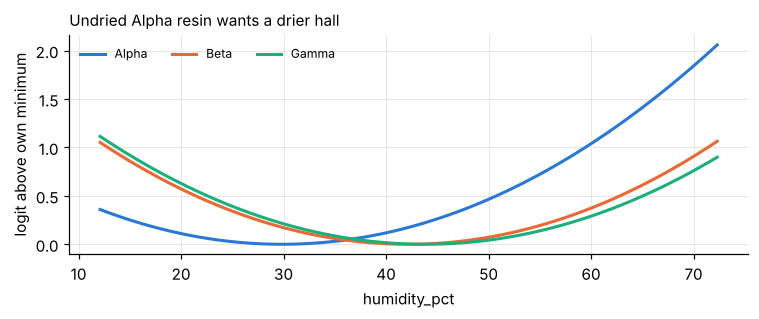

In [35]:
grid = np.linspace(model_df["humidity_pct"].min(), model_df["humidity_pct"].max(), 100)
fig, ax = plt.subplots(figsize=(7, 3))
for s in ["Alpha", "Beta", "Gamma"]:
    b = full.params
    curve = b[f"C(supplier_name)[{s}]:humidity_pct"] * grid + b[f"C(supplier_name)[{s}]:I(humidity_pct ** 2)"] * grid**2
    ax.plot(grid, curve - curve.min(), color=colors[s], lw=2, label=s)
ax.set_xlabel("humidity_pct"); ax.set_ylabel("logit above own minimum")
ax.legend(frameon=False, fontsize=8, ncol=3)
ax.set_title("Undried Alpha resin wants a drier hall", loc="left", fontsize=10)
plt.tight_layout()

In [36]:
rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    s = model_df.sample(len(model_df), replace=True, random_state=rng.integers(1 << 31))
    boot.append(optimum(smf.ols(full_formula, s).fit().params, "Alpha"))
lo, hi = np.percentile(boot, [2.5, 97.5])
h_star = optimum(full.params, "Alpha")
answers["C2_optimal_humidity_pct"] = round(float(h_star), 1)
print(f"Alpha humidity optimum: {h_star:.1f} %  (bootstrap 95% CI {lo:.1f}-{hi:.1f})")

Alpha humidity optimum: 29.8 %  (bootstrap 95% CI 29.0-30.5)


The humidity curve clearly differs by supplier. Undried Alpha resin has its lowest defect rate in a much drier hall than the pre-dried resins, and a single curve fitted to all batches lands between the two. Once the plant runs on Alpha only, the humidity setpoint should follow Alpha's own curve, not the pooled one.

### 3.3 What would regular mold cleaning have saved?

In [37]:
plan = model_df["days_since_cleaning"] % 14   # an extra cleaning whenever 14 days have passed
ratio = expected_rate(full, model_df, days_since_cleaning=plan) / expected_rate(full, model_df)
observed = answers["A3_overall_defect_rate"]
rest = df[~df["production_date"].dt.month.isin([7, 8])]
naive = rest["defective_units"].sum() / rest["units_produced"].sum()
answers["C3_rate_with_regular_cleaning"] = round(float(observed * ratio), 5)
print(f"expected change in defects: {100 * (ratio - 1):.1f} %")
print(f"observed rate {observed:.5f} -> with regular cleaning {observed * ratio:.5f}")
print(f"(naive: the rate outside July and August, {naive:.5f}, also removes the hot-season, L2 and L3 QC effects)")

expected change in defects: -5.7 %
observed rate 0.05503 -> with regular cleaning 0.05188
(naive: the rate outside July and August, 0.05045, also removes the hot-season, L2 and L3 QC effects)


The model keeps every other condition of each batch as it was and only shortens the time since cleaning, so the answer isolates the cleaning effect. Comparing summer with the rest of the year would overstate it, because summer also brings hotter molds and falls after the L2 regime change.

## Answer

In [38]:
Path("reference_answer.json").write_text(json.dumps(answers, indent=2) + "\n")
print(json.dumps(answers, indent=2))

{
  "A1_unique_batches": 3000,
  "A2_missing_humidity_batches": 226,
  "A3_overall_defect_rate": 0.05503,
  "A4_median_mold_temp_c": 211.6,
  "B3_regime_change": {
    "line": "L2",
    "date": "2025-06-16"
  },
  "B1_direct_drivers": [
    "cycle_time_s",
    "humidity_pct",
    "mold_temp",
    "shift"
  ],
  "B2_leakage_columns": [
    "qc_inspection_min",
    "rework_cost_eur"
  ],
  "C1_best_supplier": "Gamma",
  "C2_optimal_humidity_pct": 29.8,
  "C3_rate_with_regular_cleaning": 0.05188
}


## 4. Check against the answer key

*This section uses `eval/ground_truth.json`, which no model ever sees, and the benchmark's own scorer (`edabench.scorer`, defined in `docs/measure.md`).*

In [39]:
from edabench.scorer import score_text

gt = json.loads(Path("../eval/ground_truth.json").read_text())
result = score_text(json.dumps(answers), gt)
print("total:", result["total"], "| sections:", result["sections"])
pd.DataFrame(result["questions"]).set_index("qid")[["score", "weight", "answer", "truth"]]

total: 0.989246 | sections: {'describe': 0.980654, 'salient_features': 1.0, 'interpret': 0.985956}


,score,weight,answer,truth
qid,,,,
A1,1.000000,0.07,3000,3000
A2,1.000000,0.07,226,226
A3,0.999541,0.07,0.05503,0.055032
A4,0.923077,0.07,211.6,211.5
B1,1.000000,0.14,"[cycle_time_s, humidity_pct, mold_temp, shift]","[cycle_time_s, humidity_pct, mold_temp, shift]"
B2,1.000000,0.10,"[qc_inspection_min, rework_cost_eur]","[qc_inspection_min, rework_cost_eur]"
B3,1.000000,0.10,"{'line': 'L2', 'date': '2025-06-16'}","{'line': 'L2', 'date': '2025-06-16'}"
C1,1.000000,0.12,Gamma,Gamma
C2,0.970238,0.13,29.8,30.0
